# 04 · Demografik Saat: her ülkenin dönüm noktası

**Bu notebook ne yapıyor?**
1. Her ülkenin doğurganlık düşüşünün **dönüm noktası yılını (t₀)** buluyor.
2. "Ülkeler aynı yoldan mı geçiyor?" sorusunu test ediyor.
3. Bulduğu t₀ değerlerini `clean/t0_tablosu.csv` dosyasına kaydediyor. **05 notebook'u (para mı, okul mu?) bu dosyayı kullanacak.**

**Nasıl çalıştırılır?** Üst menüden **Run All**'a tıkla. Her hücrenin üstündeki açıklamayı oku, sonra çıktısına bak.

Bütün hesaplar **sadece 1950–2023** (gerçek tahmin) verisiyle yapılıyor. 2024 sonrası UN'in varsayımı olduğu için kullanılmıyor.

## 1. Veri

`pop2023 >= 100` kuralı K1 kararımız: 2023 nüfusu 100 binin üstündeki **200 ülke**.
`Y` tablosu: her satır bir ülke, her sütun bir yıl, hücreler TFR (kadın başına çocuk).

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

df = pd.read_csv("../clean/countries_1950_2100.csv")
df = df[df["pop2023"] >= 100]                    # K1: 200 ülke
gozlem = df[df["Time"] <= 2023]                  # sadece gerçek tahmin dönemi

Y = gozlem.pivot(index="Location", columns="Time", values="TFR")   # ülke x yıl tablosu
yil = Y.columns.values.astype(float)
print(Y.shape, "→", Y.shape[0], "ülke,", Y.shape[1], "yıl")

(200, 74) → 200 ülke, 74 yıl


## 2. S eğrisi: tek bir ülkede deneme (Türkiye)

Doğurganlık S biçiminde iner. Bu şekli 4 sayıyla tarif ediyoruz:

| Sayı | Anlamı |
|---|---|
| `U` | Başlangıç düzeyi (yokuşun tepesi) |
| `L` | Bitiş düzeyi (yokuşun dibi) |
| `t0` | **Dönüm noktası:** düşüşün en hızlı olduğu yıl |
| `k` | Düşüşün hızı |

`curve_fit`, bu 4 sayıyı eğri ile gerçek veri arasındaki fark en küçük olacak şekilde seçer (en küçük kareler).

Türkiye: U = 6.75, L = 1.89, k = 0.114, t0 = 1981.3


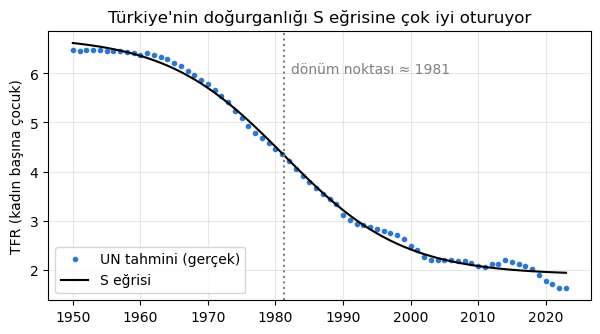

In [18]:
def s_egrisi(t, L, U, k, t0):
    return L + (U - L) / (1 + np.exp(k * (t - t0)))

tr = Y.loc["Türkiye"]
p, _ = curve_fit(s_egrisi, yil, tr.values, p0=[1.7, 6.5, 0.1, 1985])   # p0 = başlangıç tahmini
L_tr, U_tr, k_tr, t0_tr = p
print(f"Türkiye: U = {U_tr:.2f}, L = {L_tr:.2f}, k = {k_tr:.3f}, t0 = {t0_tr:.1f}")

plt.figure(figsize=(7, 3.5))
plt.plot(yil, tr.values, "o", ms=3, color="#2a78d6", label="UN tahmini (gerçek)")
plt.plot(yil, s_egrisi(yil, *p), color="black", label="S eğrisi")
plt.axvline(t0_tr, ls=":", color="gray")
plt.text(t0_tr + 1, 6, f"dönüm noktası ≈ {t0_tr:.0f}", color="gray")
plt.title("Türkiye'nin doğurganlığı S eğrisine çok iyi oturuyor")
plt.ylabel("TFR (kadın başına çocuk)"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 3. İlk deneme: her ülkeye ayrı eğri → neden yetmedi?

Aynı işi 200 ülkenin her biri için ayrı ayrı yapıyoruz. `bounds`, sayıların mantıklı aralıkta kalmasını sağlar: U en fazla 9 çocuk, L en az 0,5 çocuk, t0 1850–2150 arası.

Bir sayı bu sınırlardan birine **dayanıyorsa**, model "daha da ileri gidebilseydim giderdim" diyor demektir. Yani o ülkenin verisi 4 sayıyı belirlemeye yetmiyor.

In [19]:
sonuc = {}
for ulke in Y.index:
    p, _ = curve_fit(s_egrisi, yil, Y.loc[ulke].values, p0=[1.7, 6.5, 0.1, 1985],
                     bounds=([0.5, 1.5, 0.01, 1850], [3, 9, 1, 2150]), maxfev=20000)
    sonuc[ulke] = p
ayri = pd.DataFrame(sonuc, index=["L", "U", "k", "t0"]).T

sinirda = (ayri.U >= 8.99) | (ayri.L <= 0.51) | (ayri.t0 <= 1850.5) | (ayri.t0 >= 2149.5)
print("Sınıra dayanan ülke sayısı:", sinirda.sum(), "/", len(ayri))
ayri.loc[["Türkiye", "Japan", "Nigeria"]].round(2)

Sınıra dayanan ülke sayısı: 16 / 200


,L,U,k,t0
Türkiye,1.89,6.75,0.11,1981.32
Japan,1.28,9.00,0.05,1924.32
Nigeria,0.50,6.53,0.11,2028.40


**Ne görüyoruz?**
- **Türkiye** mantıklı: eğrinin tamamı veride var.
- **Japonya:** U = 9 çocuk. Japonya'da hiç 9 çocuk olmadı! Japonya'nın düşüşü 1950'den önce olmuş, elimizde sadece yokuşun **dibi** var.
- **Nijerya:** L = 0,5 çocuk, bu da saçma. Düşüş yeni başlıyor, elimizde sadece yokuşun **tepesi** var.

Yokuşun sadece bir parçasını görünce 4 sayıyı birden tahmin etmek mümkün değil. **Çözüm:** Yokuşun şeklini 200 ülkeden birlikte öğrenmek.

## 4. Ortak eğri: dene ve düzelt

**Fikir:** Yokuşun şekli (U, L, k) herkes için aynı. Ülkeler sadece yokuşa farklı zamanlarda giriyor (t0).

**Algoritma** (iki adım, sırayla tekrar):
1. **t0'lar sabitken:** Her ülkeyi kendi t0'ı kadar kaydır, hepsine tek bir S eğrisi oturt → U, L, k.
2. **Eğri sabitken:** Her ülke için 1850'den 2150'ye kadar bütün t0 değerlerini (0,5 yıl adımla) dene, veriye en iyi uyanı seç.

Başlangıç tahmini: TFR'nin 4,3'ün altına ilk indiği yıl. Hiç inmediyse 2040.

In [20]:
def ortak_egri(Y, turlar=8):
    yil = Y.columns.values.astype(float)
    aday = np.arange(1850, 2150.5, 0.5)                          # denenecek t0 değerleri
    t0 = Y.apply(lambda s: s[s < 4.3].index[0] if (s < 4.3).any() else 2040, axis=1).astype(float)
    for tur in range(turlar):
        # Adım 1: herkesi kendi t0'ı kadar kaydır, tek eğri oturt
        z = (yil[None, :] - t0.values[:, None]).ravel()          # "yıl − t0"
        (L, U, k), _ = curve_fit(lambda z, L, U, k: s_egrisi(z, L, U, k, 0),
                                 z, Y.values.ravel(), p0=[1.7, 7, 0.08])
        # Adım 2: her ülke için en iyi t0'ı dene
        tablo = s_egrisi(yil[None, :], L, U, k, aday[:, None])   # her aday t0 için eğri
        hata = ((tablo[None, :, :] - Y.values[:, None, :]) ** 2).sum(axis=2)
        t0 = pd.Series(aday[hata.argmin(axis=1)], index=Y.index)
    return L, U, k, t0

L, U, k, t0 = ortak_egri(Y)
print(f"Ortak eğri: U = {U:.2f}, L = {L:.2f}, k = {k:.3f}, orta nokta TFR = {(U + L) / 2:.2f}")
t0.loc[["Japan", "France", "Republic of Korea", "Türkiye", "India", "Bangladesh", "Nigeria", "Niger"]]

Ortak eğri: U = 6.97, L = 1.67, k = 0.082, orta nokta TFR = 4.32


Location
Japan                1934.5
France               1941.0
Republic of Korea    1967.5
Türkiye              1981.5
India                1986.0
Bangladesh           1993.0
Nigeria              2024.5
Niger                2150.0
dtype: float64

**Ne değişti?** Japonya artık yaklaşık 1935'te (mantıklı), Türkiye yine 1981 civarında. Nijer 2150 sınırına dayanıyor: Düşüşü daha başlamadığı için saati **belirsiz**. Bunu 7. bölümde işaretleyeceğiz.

## 5. Ana görsel: takvim zamanı ve demografik zaman

Sol: 200 ülke takvim yılına göre. Sağ: Her ülke kendi t0'ı kadar kaydırılmış. Kesikli çizgiler 2024 sonrası UN projeksiyonu.

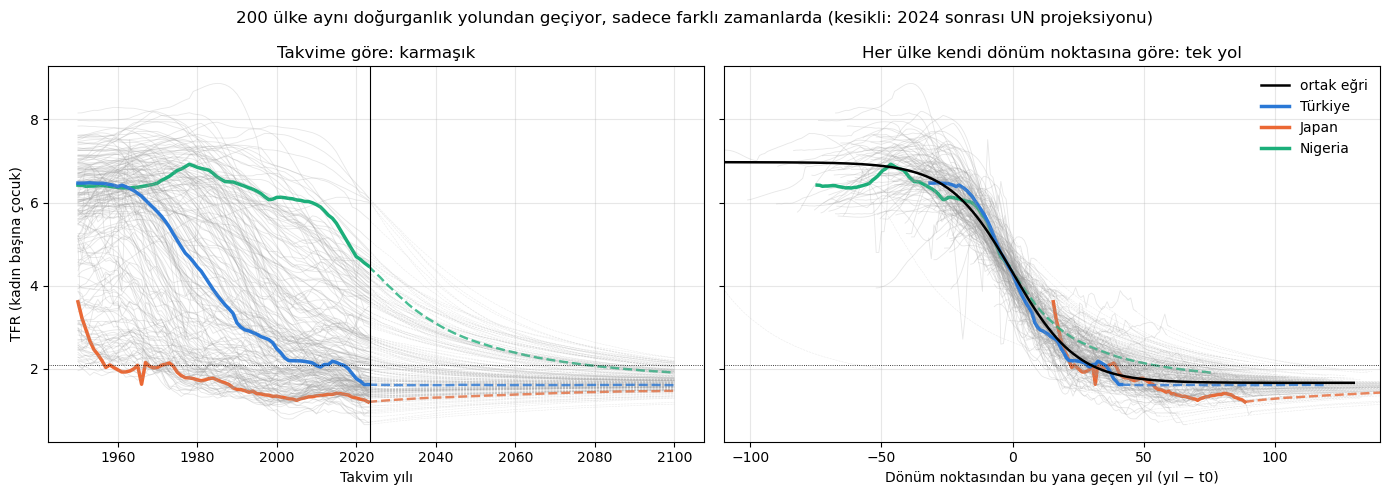

In [21]:
renk = {"Türkiye": "#2a78d6", "Japan": "#eb6834", "Nigeria": "#1baf7a"}
tum = df.pivot(index="Location", columns="Time", values="TFR")     # 1950–2100, çizim için
tyil = tum.columns.values

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for i, kaydir in enumerate([False, True]):
    for ulke in tum.index:
        x = tyil - t0[ulke] if kaydir else tyil
        r, kal, a = (renk[ulke], 2.5, 1) if ulke in renk else ("#9e9e9e", 0.6, 0.25)
        ax[i].plot(x[tyil <= 2023], tum.loc[ulke][tyil <= 2023], color=r, lw=kal, alpha=a)
        ax[i].plot(x[tyil >= 2023], tum.loc[ulke][tyil >= 2023], color=r, lw=kal * 0.7, alpha=a * 0.8, ls="--")
    ax[i].axhline(2.1, color="black", lw=0.6, ls=":")
    ax[i].grid(alpha=.3)
z = np.linspace(-110, 130, 300)
ax[1].plot(z, s_egrisi(z, L, U, k, 0), color="black", lw=1.8, label="ortak eğri")
ax[0].axvline(2023.5, color="black", lw=0.8)
ax[1].set_xlim(-110, 140)                         # saati belirsiz ülkeler (ör. Nijer) ekseni uzatmasın
ax[0].set_xlabel("Takvim yılı"); ax[1].set_xlabel("Dönüm noktasından bu yana geçen yıl (yıl − t0)")
ax[0].set_ylabel("TFR (kadın başına çocuk)")
for ulke, r in renk.items():
    ax[1].plot([], [], color=r, lw=2.5, label=ulke)
ax[1].legend(frameon=False)
ax[0].set_title("Takvime göre: karmaşık")
ax[1].set_title("Her ülke kendi dönüm noktasına göre: tek yol")
fig.suptitle("200 ülke aynı doğurganlık yolundan geçiyor, sadece farklı zamanlarda (kesikli: 2024 sonrası UN projeksiyonu)")
plt.tight_layout(); plt.savefig("../outputs/04_ayni_yol.png", dpi=150); plt.show()

## 6. Test 1: Ülkeler arasındaki farkın ne kadarını açıklıyoruz?

**R²** = farkların yüzde kaçı açıklanıyor. Üç modeli karşılaştırıyoruz:

| Model | Ne varsayıyor? |
|---|---|
| Takvim | Her yıl bütün ülkeler aynı |
| Düzey kayması | Ortak eğri, her ülke biraz daha yukarıda ya da aşağıda (ülke başına 1 sayı) |
| Zaman kayması | Ortak eğri, her ülke farklı zamanda (ülke başına 1 sayı, yani t0) |

Düzey ve zaman kaymasında ülke başına **aynı sayıda** parametre var. Bu yüzden karşılaştırma adil.

In [22]:
def r2(gercek, tahmin):
    return 1 - ((gercek - tahmin) ** 2).sum() / ((gercek - gercek.mean()) ** 2).sum()

y = Y.values
tahmin_takvim = np.tile(Y.mean().values, (len(Y), 1))

a = np.zeros(len(Y))                                   # düzey kayması: dene ve düzelt
for _ in range(15):
    pd_, _ = curve_fit(s_egrisi, np.tile(yil, len(Y)), (y - a[:, None]).ravel(), p0=[1.7, 7, 0.08, 1985])
    egri = s_egrisi(yil, *pd_)
    a = (y - egri).mean(axis=1)
tahmin_duzey = egri[None, :] + a[:, None]

tahmin_zaman = s_egrisi(yil[None, :], L, U, k, t0.values[:, None])

r2_tablo = pd.Series({"Takvim": r2(y, tahmin_takvim),
                      "Düzey kayması": r2(y, tahmin_duzey),
                      "Zaman kayması (Demografik Saat)": r2(y, tahmin_zaman)}).round(3)
r2_tablo

Takvim                             0.270
Düzey kayması                      0.870
Zaman kayması (Demografik Saat)    0.943
dtype: float64

## 7. Test 2: Geleceği tahmin edebiliyor mu? (geriye dönük test)

Modeli belli bir yıla kadarki veriyle kuruyoruz ve **20 yıl sonrasını** tahmin ettiriyoruz. Sonra gerçek değerle karşılaştırıyoruz. Bunu 3 farklı başlangıç yılıyla yapıyoruz.

- **Naif:** "Hiçbir şey değişmez", son değer aynen kalır.
- **Ülke ülke:** 3. bölümdeki ayrı eğriler.
- **Ortak eğri:** 4. bölümdeki model.

İki hata ölçüsü kullanıyoruz:
- **Medyan mutlak hata:** Tipik bir ülkede kaç çocuk yanıldık?
- **RMSE:** Büyük hatalara daha çok ceza verir.

In [23]:
satirlar = []
for bas in [1983, 1993, 2003]:
    E = Y.loc[:, :bas]                                  # sadece başlangıç yılına kadar
    hedef = bas + 20
    gercek = Y[hedef].values
    naif = E[bas].values
    Le, Ue, ke, t0e = ortak_egri(E)
    ortak = s_egrisi(hedef, Le, Ue, ke, t0e.values)
    ulke_ulke = []
    for ulke in E.index:
        p, _ = curve_fit(s_egrisi, E.columns.values.astype(float), E.loc[ulke].values, p0=[1.7, 6.5, 0.1, 1985],
                         bounds=([0.5, 1.5, 0.01, 1850], [3, 9, 1, 2150]), maxfev=20000)
        ulke_ulke.append(s_egrisi(hedef, *p))
    for ad, tah in [("Naif", naif), ("Ülke ülke", np.array(ulke_ulke)), ("Ortak eğri", ortak)]:
        satirlar.append({"Başlangıç": f"{bas} → {hedef}", "Yöntem": ad,
                         "Medyan mutlak hata": np.median(np.abs(tah - gercek)),
                         "RMSE": np.sqrt(np.mean((tah - gercek) ** 2))})
backtest = pd.DataFrame(satirlar).pivot(index="Başlangıç", columns="Yöntem")
backtest.round(2)

Medyan mutlak hata                       RMSE                     
Yöntem                    Naif Ortak eğri Ülke ülke  Naif Ortak eğri Ülke ülke
Başlangıç                                                                     
1983 → 2003               1.11       0.49      0.56  1.61       1.21      0.99
1993 → 2013               0.77       0.38      0.56  1.18       0.91      0.94
2003 → 2023               0.59       0.41      0.51  0.97       0.81      0.82

**Nasıl okunur?** Ortak eğri, **tipik bir ülke için** (medyan) üç denemede de en az hatayı yapıyor. RMSE'de sonuç karışık: Ortak eğri birkaç ülkede büyük hata yapabiliyor. Bunu sunumda dürüstçe söyleyeceğiz.

Yani ortak eğriyi seçmemizin asıl sebebi tahmin değil, **anlamlı sayılar** vermesi (3. bölüm). Tahminde de en az ülke ülke eğri kadar iyi.

## 8. Güvenilirlik ve kayıt

Bir ülkenin dönüm noktası ancak düşüşün **iki yanı da** veride görülüyorsa güvenilir olur. Yani TFR, ortak eğrinin orta noktasının (yaklaşık 4,3) hem belirgin üstünde hem belirgin altında gözlenmiş olmalı.

- `guvenilir = True`: dönüm noktası 1950–2023 arasında gerçekten yaşanmış.
- Japonya ve Fransa gibi düşüşü 1950'den önce olanlar ile Nijer gibi düşüşü yeni başlayanlar `False` olur.

In [24]:
orta = (U + L) / 2
guvenilir = (Y.max(axis=1) > orta + 0.5) & (Y.min(axis=1) < orta - 0.5)

bilgi = df.drop_duplicates("Location").set_index("Location")[["LocID", "ISO3_code", "bolge", "pop2023"]]
t0_tablo = bilgi.join(t0.rename("t0")).join(guvenilir.rename("guvenilir"))
t0_tablo["saat_2023"] = 2023 - t0_tablo["t0"]          # 2023'te dönüm noktasından bu yana geçen yıl
t0_tablo.to_csv("../clean/t0_tablosu.csv")

print("Güvenilir t0:", guvenilir.sum(), "/", len(t0_tablo), "ülke")
print(t0_tablo.groupby("bolge")["guvenilir"].agg(["sum", "count"]))
t0_tablo.loc[["Türkiye", "Japan", "Nigeria", "Niger"]]

Güvenilir t0: 115 / 200 ülke
                                 sum  count
bolge                                      
Africa                            25     57
Asia                              44     51
Europe                             4     41
Latin America and the Caribbean   32     36
Northern America                   0      2
Oceania                           10     13


,LocID,ISO3_code,bolge,pop2023,t0,guvenilir,saat_2023
Location,,,,,,,
Türkiye,792,TUR,Asia,87270.502,1981.5,True,41.5
Japan,392,JPN,Asia,124370.947,1934.5,False,88.5
Nigeria,566,NGA,Africa,227882.945,2024.5,False,-1.5
Niger,562,NER,Africa,26159.867,2150.0,False,-127.0


## 🟡 Sorular (cevapları bana yaz)

1. **6. bölüm:** Zaman kayması ile düzey kaymasının R² değerleri ne? Karşılaştırma neden adil?
2. **3. bölüm:** Kaç ülke sınıra dayandı? Japonya'nın U değerine bak: Neden bu sayı saçma?
3. **8. bölüm:** Hangi bölgede güvenilir t0'ı olan ülke oranı en düşük? Sence neden?